In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import pandas as pd
import json
from tqdm import tqdm
import numpy as np
import seaborn as sns
import pickle
import scipy.stats as stats
import csv

In [11]:
## Matplotlib defaults ##

colors = {"archaea": "#D55E00", 
         "bacteria": "#0977B5",
         "eukarya": "#E69F00",
         "metagenome": "#009E73",
         "pantaxa": "#EA9999",
          "chiral": "#34CCFF",
          "achiral": "#FFC012",
          "mixed": "#abdbfc",
          "luca": "grey"}

font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.style.use("default")
plt.rcParams.update({'font.size': 22})

In [3]:
def process_expansion(fpath):
  with open(fpath) as f:
    #load file and create a dataframe called "generations"
    datajson = json.load(f)
    generations = pd.DataFrame(datajson["generations"])
    generations = generations.transpose()
    generations.index = generations.index.astype(int)
    generations = generations.sort_index()
    original_columns = generations.columns

    #Add n columns
    for col in original_columns:
        generations["n_"+col] = generations[col].str.len() 

    return generations

In [4]:
df = pd.read_csv("Data/rxn_sub0_prod0.csv")
zero_zero_rxns = list(df["rxn"])
print(f"0 -> 0 {zero_zero_rxns}")

df = pd.read_csv("Data/rxn_sub0_prod1.csv")
zero_one_rxns = list(df["rxn"])
print(f"0 -> 1 {zero_one_rxns}")

df = pd.read_csv("Data/rxn_sub1_prod1.csv")
one_one_rxns = list(df["rxn"])
print(f"1 -> 1 {one_one_rxns}")

df = pd.read_csv("Data/rxn_sub1_prod0.csv")
one_zero_rxns = list(df["rxn"])
print(f"1 -> 0 {one_zero_rxns}")

df = pd.read_csv("Data/rxn_sub1_prod2.csv")
one_two_rxns = list(df["rxn"])
print(f"1 -> 2 {one_two_rxns}")

df = pd.read_csv("Data/rxn_sub2_prod2.csv")
two_two_rxns = list(df["rxn"])
print(f"2 -> 2 {two_two_rxns}")

### Testing: chiral generating, chiral conserving, and chiral destroying
chiral_generate_rxns = []
for x, y in [(0,1), (1,2), (2,3), (3,4), (0,2), (1,3), (2,4)]:
    df = pd.read_csv(f"Data/rxn_sub{x}_prod{y}.csv")
    chiral_generate_rxns.extend(list(df["rxn"]))
print(len(chiral_generate_rxns))

chiral_conserve_rxns = []
for x, y in [(0,0), (1,1), (2,2), (3,3), (4,4)]:
    df = pd.read_csv(f"Data/rxn_sub{x}_prod{y}.csv")
    chiral_conserve_rxns.extend(list(df["rxn"]))
print(len(chiral_conserve_rxns))

chiral_destroy_rxns = []
for x, y in [(1,0), (2,1), (3,2), (4,3), (2,0), (3,1), (4,2)]:
    df = pd.read_csv(f"Data/rxn_sub{x}_prod{y}.csv")
    chiral_destroy_rxns.extend(list(df["rxn"]))
print(len(chiral_destroy_rxns))

fpath = "Data/primordial.dat0.json"
primordial_generations = process_expansion(fpath)

zerozero_counts = []
zeroone_counts = []
oneone_counts = []
onetwo_counts = []
twotwo_counts = []
chiral_generate_counts = []
chiral_conserve_counts = []
chiral_destroy_counts = []

for _, row in primordial_generations.iterrows():
    rxns_new = row["reactions_new"]
    zerozero_counts.append(sum(r in zero_zero_rxns for r in rxns_new))
    zeroone_counts.append(sum(r in zero_one_rxns for r in rxns_new))
    oneone_counts.append(sum(r in one_one_rxns for r in rxns_new))
    onetwo_counts.append(sum(r in one_two_rxns for r in rxns_new))
    twotwo_counts.append(sum(r in two_two_rxns for r in rxns_new))
    chiral_generate_counts.append(sum(r in chiral_generate_rxns for r in rxns_new))
    chiral_conserve_counts.append(sum(r in chiral_conserve_rxns for r in rxns_new))
    chiral_destroy_counts.append(sum(r in chiral_destroy_rxns for r in rxns_new))


0 -> 0 ['R08252', 'R10097', 'R11131', 'R01004', 'R01003', 'R01268', 'R08513', 'R02003', 'R02009', 'R10216', 'R10213', 'R06855', 'R06854', 'R06850', 'R06853', 'R06852', 'R04985', 'R04986', 'R04982', 'R08315', 'R08316', 'R11168', 'R03510', 'R07522', 'R07523', 'R07520', 'R07526', 'R07525', 'R07528', 'R01854', 'R01851', 'R01853', 'R03180', 'R03181', 'R06699', 'R09285', 'R05001', 'R05000', 'R09284', 'R08319', 'R05445', 'R07982', 'R08400', 'R09250', 'R09251', 'R04538', 'R08375', 'R08373', 'R11602', 'R08370', 'R10979', 'R10978', 'R10975', 'R10976', 'R11086', 'R11087', 'R00539', 'R00533', 'R03370', 'R02397', 'R02394', 'R02398', 'R05615', 'R05612', 'R05613', 'R05611', 'R10766', 'R10761', 'R06871', 'R06870', 'R00080', 'R00082', 'R00083', 'R00084', 'R08620', 'R11148', 'R04258', 'R03575', 'R08624', 'R08888', 'R08889', 'R06679', 'R06678', 'R06671', 'R06673', 'R06672', 'R02564', 'R10212', 'R11344', 'R11611', 'R00610', 'R04732', 'R04731', 'R11617', 'R00618', 'R05280', 'R05284', 'R05287', 'R09276', 'R

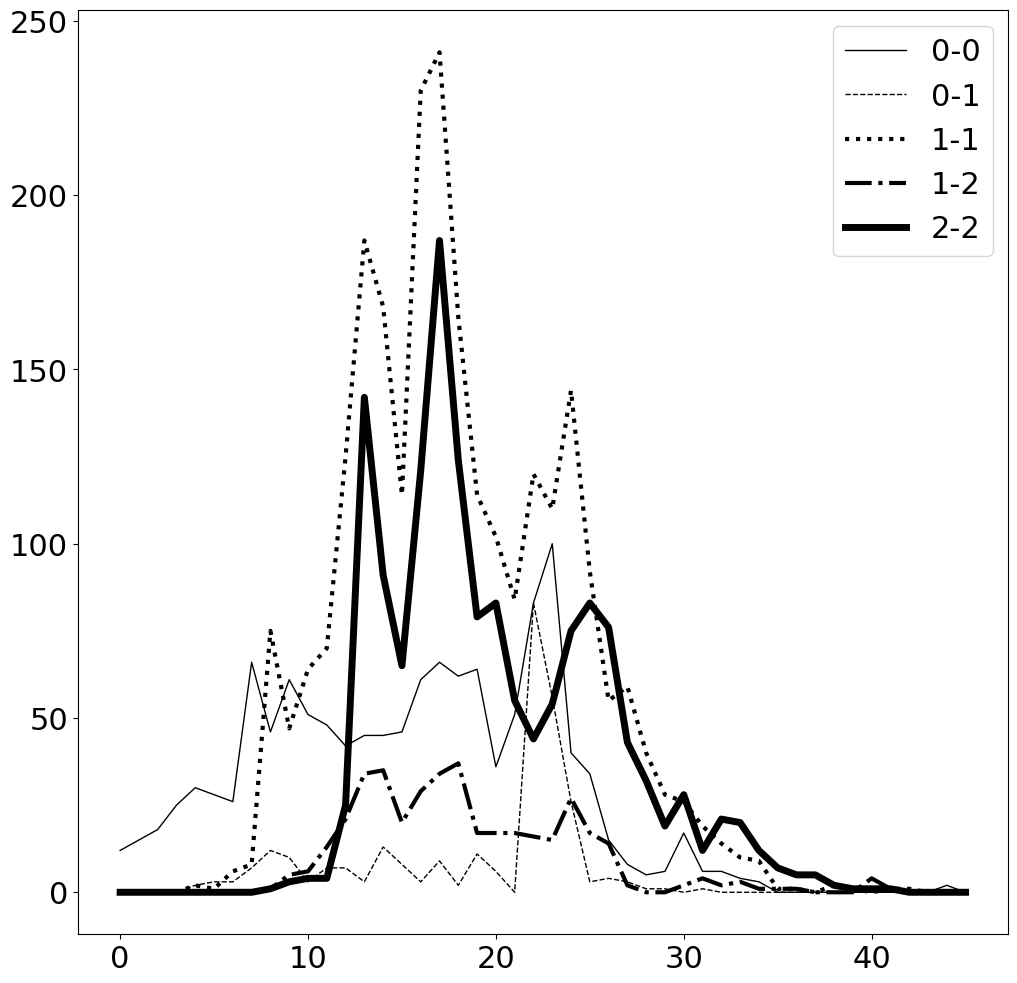

In [23]:
fig, ax = plt.subplots(figsize=(12,12))

ax.plot(zerozero_counts, linestyle="solid", linewidth=1, color='k', label="0-0")
ax.plot(zeroone_counts, linestyle="dashed", linewidth=1, color='k', label="0-1")
ax.plot(oneone_counts, linestyle="dotted", linewidth=3, color='k', label="1-1")
ax.plot(onetwo_counts, linestyle="dashdot", linewidth=3, color='k', label="1-2")
ax.plot(twotwo_counts, linestyle="solid", linewidth=5, color='k', label="2-2")

plt.legend()

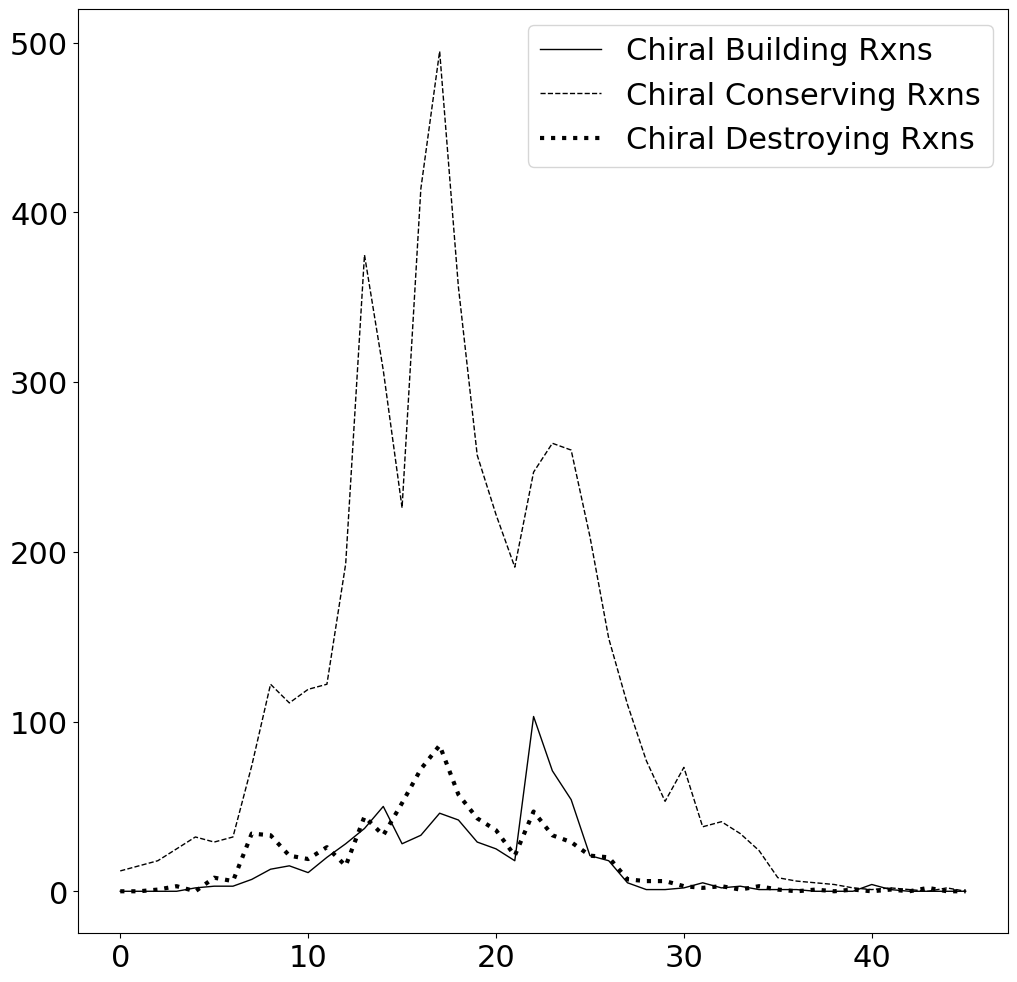

In [41]:
fig, ax = plt.subplots(figsize=(12,12))

ax.plot(chiral_generate_counts, linestyle="solid", linewidth=1, color='k', label="Chiral Building Rxns")
ax.plot(chiral_conserve_counts, linestyle="dashed", linewidth=1, color='k', label="Chiral Conserving Rxns")
ax.plot(chiral_destroy_counts, linestyle="dotted", linewidth=3, color='k', label="Chiral Destroying Rxns")
# ax.plot(onetwo_counts, linestyle="dashdot", linewidth=3, color='k', label="1-2")
# ax.plot(twotwo_counts, linestyle="solid", linewidth=5, color='k', label="2-2")

plt.legend()

Text(0, 0.5, 'Reaction Count')

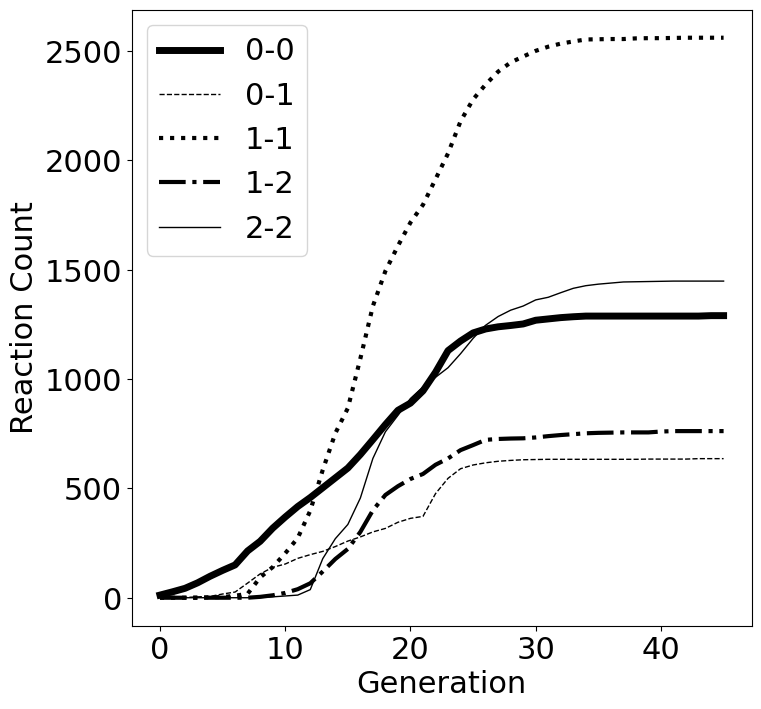

In [28]:
fig, ax = plt.subplots(figsize=(8,8))

ax.plot(list(np.cumsum(np.array(zerozero_counts))), linestyle="solid", linewidth=5, color='k', label="0-0")
ax.plot(list(np.cumsum(np.array(zeroone_counts))), linestyle="dashed", linewidth=1, color='k', label="0-1")
ax.plot(list(np.cumsum(np.array(oneone_counts))), linestyle="dotted", linewidth=3, color='k', label="1-1")
ax.plot(list(np.cumsum(np.array(onetwo_counts))), linestyle="dashdot", linewidth=3, color='k', label="1-2")
ax.plot(list(np.cumsum(np.array(twotwo_counts))), linestyle="solid", linewidth=1, color='k', label="2-2")

plt.legend()
plt.xlabel("Generation")
plt.ylabel("Reaction Count")

Text(0, 0.5, 'Reaction Count')

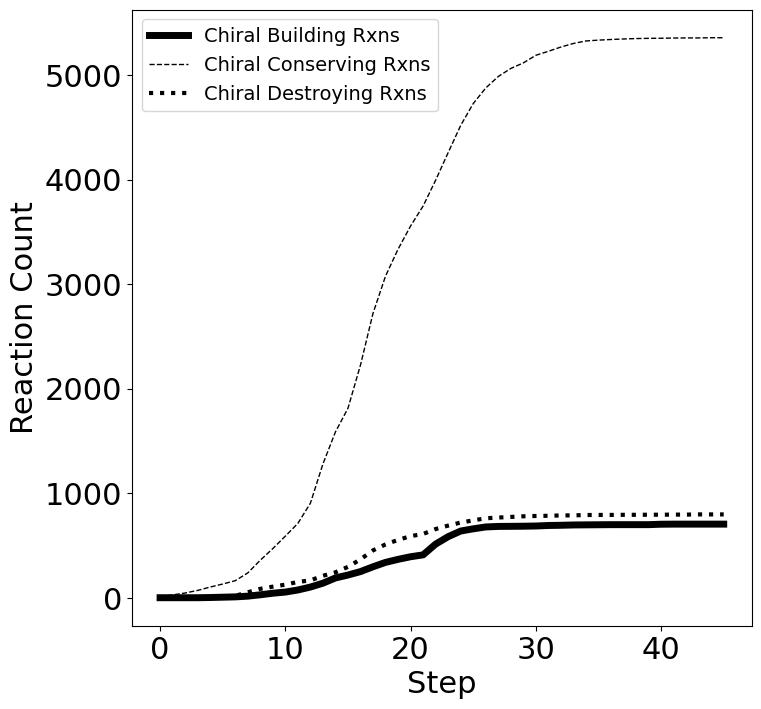

In [57]:
fig, ax = plt.subplots(figsize=(8,8))

ax.plot(list(np.cumsum(np.array(chiral_generate_counts))), 
        linestyle="solid", linewidth=5, color='k', label="Chiral Building Rxns")
ax.plot(list(np.cumsum(np.array(chiral_conserve_counts))), 
        linestyle="dashed", linewidth=1, color='k', label="Chiral Conserving Rxns")
ax.plot(list(np.cumsum(np.array(chiral_destroy_counts))), linestyle="dotted", 
        linewidth=3, color='k', label="Chiral Destroying Rxns")

plt.legend(loc="upper left", prop={"size":14})
plt.xlabel("Step")
plt.ylabel("Reaction Count")

In [17]:
### Modulating - from Kamesh

modulate_df = pd.read_csv("Data/kegg_reactions_with_mol_weights_comprehensive_v8.csv")

print(modulate_df)

modulating = []
achiral_conserve = []
chiral_conserve = []

modulating_rxns = []
achiral_conserving_rxns = []
chiral_conserving_rxns = []

for i in range(0, max(modulate_df["Network_step"])):
    sub_df = modulate_df[modulate_df["Network_step"] == i]

    chiral_modulating_df = sub_df[sub_df["Chiral_modulating"] == 1]
    modulating.append(len(chiral_modulating_df))
    if not chiral_modulating_df.empty:
        modulating_rxns.extend(list(chiral_modulating_df["_key"]))
    
    achiral_conserving_df = sub_df[sub_df["Achiral_conserving"] == 1]
    achiral_conserve.append(len(achiral_conserving_df))
    if not achiral_conserving_df.empty:
        achiral_conserving_rxns.extend(list(achiral_conserving_df["_key"]))

    
    chiral_conserving_df = sub_df[sub_df["Chiral_conserving"] == 1]
    chiral_conserve.append(len(chiral_conserving_df))
    if not chiral_conserving_df.empty:
        chiral_conserving_rxns.extend(list(chiral_conserving_df["_key"]))

print(modulating)
print(achiral_conserve)
print(chiral_conserve)

print(modulating_rxns)

    

        _key                                  Reaction_class  \
0     R00004                                               0   
1     R00005                          RC02756, C00011_C01010   
2     R00006                          RC00106, C00022_C00900   
3     R00008  RC00502, C00022_C06033, RC01205, C00022_C06033   
4     R00009                          RC02755, C00007_C00027   
...      ...                                             ...   
6853  R11791                          RC00059, C00031_C00252   
6854  R11793  RC00064, C21620_C21663, RC00090, C00025_C21620   
6855  R11801  RC00039, C00229_C01271, RC00064, C00077_C21680   
6856  R11803  RC00002, C00002_C00008, RC00017, C03393_C21593   
6857  R11805                          RC00556, C00218_C00543   

                   Enzyme                                            Pathway  \
0                 3.6.1.1                                                  0   
1                3.5.1.54  rn00220, Arginine biosynthesis, rn00791, Atr

Text(0, 0.5, 'Reaction Count')

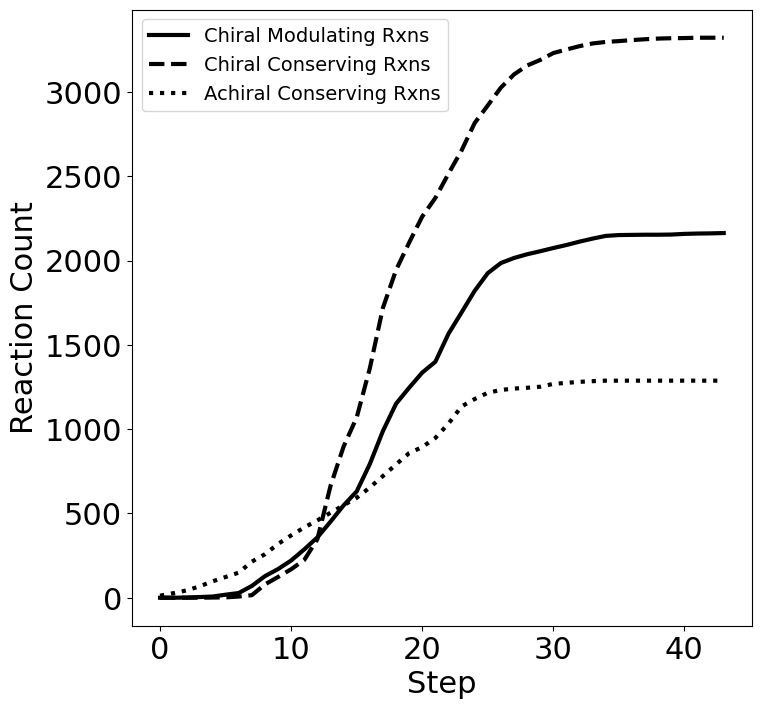

In [12]:
fig, ax = plt.subplots(figsize=(8,8))

ax.plot(list(np.cumsum(np.array(modulating))), 
        linestyle="solid", linewidth=3, color='k', label="Chiral Modulating Rxns")
ax.plot(list(np.cumsum(np.array(chiral_conserve))), 
        linestyle="dashed", linewidth=3, color='k', label="Chiral Conserving Rxns")
ax.plot(list(np.cumsum(np.array(achiral_conserve))), linestyle="dotted", 
        linewidth=3, color='k', label="Achiral Conserving Rxns")

plt.legend(loc="upper left", prop={"size":14})
plt.xlabel("Step")
plt.ylabel("Reaction Count")

### Get specific stats for manuscript

- Percentage of each type at final step
- Steps where chiral modulating reactions outnumber chiral conserving

In [34]:
cum_Modulating = np.cumsum(modulating)
cum_chiralConserving = np.cumsum(chiral_conserve)
cum_achiralConserving = np.cumsum(achiral_conserve)
print(f"Final chiral modulating count: {cum_Modulating[-1]}")
print(f"Final chiral conserving count: {cum_chiralConserving[-1]}")
print(f"Final achiral conserving count: {cum_achiralConserving[-1]}")

print(f"Final chiral modulating percentage: {cum_Modulating[-1] / (cum_Modulating[-1] + cum_chiralConserving[-1] + cum_achiralConserving[-1])}")
print(f"Final chiral conserving percentage: {cum_chiralConserving[-1] / (cum_Modulating[-1] + cum_chiralConserving[-1] + cum_achiralConserving[-1])}")
print(f"Final achiral conserving percentage: {cum_achiralConserving[-1] / (cum_Modulating[-1] + cum_chiralConserving[-1] + cum_achiralConserving[-1])}")


Final chiral modulating count: 2164
Final chiral conserving count: 3323
Final achiral conserving count: 1288
Final chiral modulating percentage: 0.31940959409594094
Final chiral conserving percentage: 0.49047970479704794
Final achiral conserving percentage: 0.19011070110701106


In [38]:
for i in range(len(cum_Modulating)):
    if cum_Modulating[i] >= cum_chiralConserving[i]:
        print(f"Step {i}: Modulating={cum_Modulating[i]}, Chiral Conserving={cum_chiralConserving[i]}")

Step 0: Modulating=0, Chiral Conserving=0
Step 1: Modulating=0, Chiral Conserving=0
Step 2: Modulating=1, Chiral Conserving=0
Step 3: Modulating=4, Chiral Conserving=0
Step 4: Modulating=7, Chiral Conserving=1
Step 5: Modulating=18, Chiral Conserving=2
Step 6: Modulating=28, Chiral Conserving=7
Step 7: Modulating=70, Chiral Conserving=15
Step 8: Modulating=128, Chiral Conserving=79
Step 9: Modulating=170, Chiral Conserving=123
Step 10: Modulating=221, Chiral Conserving=169
Step 11: Modulating=287, Chiral Conserving=224
Step 12: Modulating=358, Chiral Conserving=347


### Re-make Reaction Heatmap

Need NxM array - N is rows, M is columns

In [18]:
total_rxns = len(zero_zero_rxns) + len(zero_one_rxns) + len(one_zero_rxns) + len(one_one_rxns) + len(one_two_rxns) + len(two_two_rxns)

heatmap_array = []

#Add zeros row to heatmap array
heatmap_array.append([len(zero_zero_rxns)/total_rxns, len(zero_one_rxns)/total_rxns, 0])
#Add ones
heatmap_array.append([len(one_zero_rxns)/total_rxns, len(one_one_rxns)/total_rxns, len(one_two_rxns)/total_rxns])
#Add twos
heatmap_array.append([0, 0, len(two_two_rxns)/total_rxns])

print(heatmap_array)


[[0.19485678444490906, 0.03752874764791972, 0], [0.04568262596696634, 0.4037215136943341, 0.05833159105164123], [0, 0, 0.25987873719422955]]


[[1864, 359, 5, 0, 0], [437, 3862, 558, 6, 0], [6, 525, 2486, 28, 4], [0, 7, 93, 33, 6], [0, 0, 1, 6, 1]]


Text(0, 0.5, 'Total Reactions')

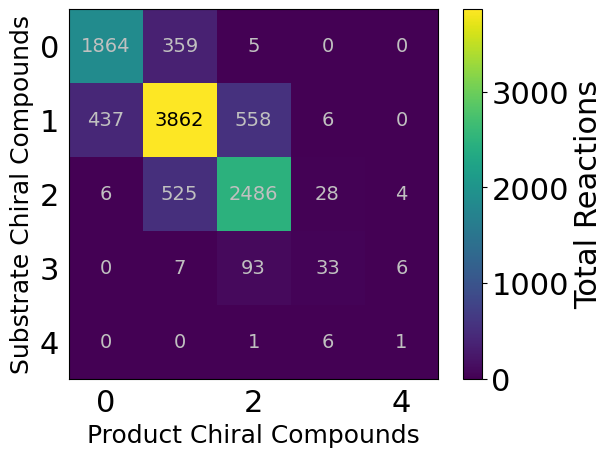

In [19]:
### Test heatmap (from updated numbers)


heatmap_array = []
total = 0

for i in range(5):
    row = []
    for j in range(5):
        rxn_df = pd.read_csv(f"Data/rxn_sub{i}_prod{j}.csv")
        row.append(len(rxn_df))
        total += (len(rxn_df))
    heatmap_array.append(row)
# #Add zeros row to heatmap array
# heatmap_array.append([len(zero_zero_rxns)/total_rxns, len(zero_one_rxns)/total_rxns, 0])
# #Add ones
# heatmap_array.append([len(one_zero_rxns)/total_rxns, len(one_one_rxns)/total_rxns, len(one_two_rxns)/total_rxns])
# #Add twos
# heatmap_array.append([0, 0, len(two_two_rxns)/total_rxns])

print(heatmap_array)

fig, ax = plt.subplots()
im = ax.imshow(heatmap_array)

#ax.set_yticklabels(["", 0, "", 1, "", 2])

ax.tick_params(
    axis='both',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    left=False)   

ax.set_ylabel("Substrate Chiral Compounds", fontsize=18)
ax.set_xlabel("Product Chiral Compounds", fontsize=18)

for i in range(5):
    for j in range(5):
        if i == 1 and j == 1:
            c = "k"
        else:
            c = "silver"
        text = ax.text(j, i, heatmap_array[i][j],
                       ha = "center", va = "center", color = c, fontsize=14)

# Add the color bar
cbar = ax.figure.colorbar(im, ax = ax)
cbar.ax.set_ylabel("Total Reactions")


/Users/johnmalloy/opt/miniconda3/envs/my-rdkit-env/lib/python3.7/site-packages/ipykernel_launcher.py:4: UserWarning: FixedFormatter should only be used together with FixedLocator
  after removing the cwd from sys.path.


Text(0, 0.5, '% Total Reactions')

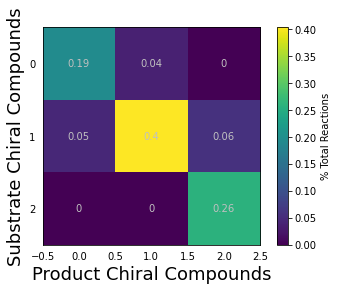

In [10]:
fig, ax = plt.subplots()
im = ax.imshow(heatmap_array)

ax.set_yticklabels(["", 0, "", 1, "", 2])

ax.tick_params(
    axis='both',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    left=False)   

ax.set_ylabel("Substrate Chiral Compounds", fontsize=18)
ax.set_xlabel("Product Chiral Compounds", fontsize=18)

for i in range(3):
    for j in range(3):
        text = ax.text(j, i, round(heatmap_array[i][j], 2),
                       ha = "center", va = "center", color = "silver")

# Add the color bar
cbar = ax.figure.colorbar(im, ax = ax)
cbar.ax.set_ylabel("% Total Reactions")


In [20]:
def plot_classes(universality, ax, c, title):

    # zero_zero_universality = [u for r, u in universality.items() if r in zero_zero_rxns]
    # zero_one_universality = [u for r, u in universality.items() if r in zero_one_rxns]
    # one_one_universality = [u for r, u in universality.items() if r in one_one_rxns]
    # one_two_universality = [u for r, u in universality.items() if r in one_two_rxns]
    # two_two_universality = [u for r, u in universality.items() if r in two_two_rxns]

    modulating_universality = [u for r, u in universality.items() if r in modulating_rxns]
    chiral_conserve_universality = [u for r, u in universality.items() if r in chiral_conserving_rxns]
    achiral_conserve_universality = [u for r, u in universality.items() if r in achiral_conserving_rxns]

    # ax.plot(zero_zero_universality, linestyle="solid", linewidth=5, color=c, label="0-0")
    # ax.plot(zero_one_universality, linestyle="dashed", linewidth=1, color=c, label="0-1")
    # ax.plot(one_one_universality, linestyle="dotted", linewidth=3, color=c, label="1-1")
    # ax.plot(one_two_universality, linestyle="dashdot", linewidth=3, color=c, label="1-2")
    # ax.plot(two_two_universality, linestyle="solid", linewidth=1, color=c, label="2-2")

    ax.plot(modulating_universality, linestyle="solid", linewidth=3, color=c, label="Chiral Modulating")
    ax.plot(chiral_conserve_universality, linestyle="dashed", linewidth=3, color=c, label="Chiral Conserving")
    ax.plot(achiral_conserve_universality, linestyle="dotted", linewidth=3, color=c, label="Achiral Conserving")

    ax.legend(prop={"size": 8})
    ax.set_title(title, color=c)

In [21]:
#Read in occurence data & create universality percentages

num_bacteria = 11759
num_archaea = 1282
num_eukarya = 243
num_metagenomes = 18725

with open("Data/Archaea_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  a_rxn_occurances = dict(reader)

with open("Data/Bacteria_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  b_rxn_occurances = dict(reader)

with open("Data/Eukaryota_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  e_rxn_occurances = dict(reader)

with open("Data/Metagenome_occurance_rxn.csv") as f:
  next(f)
  reader = csv.reader(f, skipinitialspace=True)
  m_rxn_occurances = dict(reader)

#Translate occurances into % universality
a_rxn_universality = {}
b_rxn_universality = {}
e_rxn_universality = {}
m_rxn_universality = {}

#Num archaea: 1194
for item in a_rxn_occurances.items():
  a_rxn_universality[item[0]] = float(item[1]) / num_archaea

#num bacteria = 10434
for item in b_rxn_occurances.items():
  b_rxn_universality[item[0]] = float(item[1]) / num_bacteria

#Num eukarya: 267
for item in e_rxn_occurances.items():
  e_rxn_universality[item[0]] = float(item[1]) / num_eukarya

#Num metagenomes = 6112
for item in m_rxn_occurances.items():
  m_rxn_universality[item[0]] = float(item[1]) / num_metagenomes

TypeError: plot_classes() takes 4 positional arguments but 9 were given

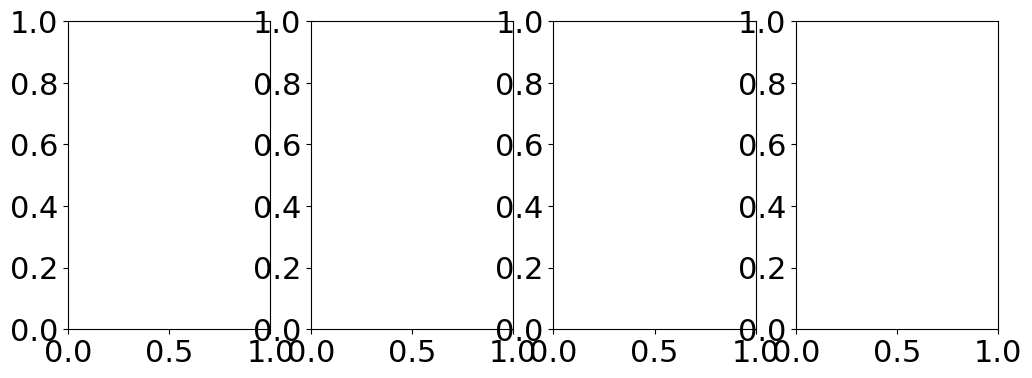

In [22]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(12,4))
gs = GridSpec(1,4)

ax_archaea = fig.add_subplot(gs[0, 0])
ax_bacteria = fig.add_subplot(gs[0,1])
ax_eukarya= fig.add_subplot(gs[0, 2])
ax_mg = fig.add_subplot(gs[0, 3])

plot_classes(zero_zero_rxns, zero_one_rxns, one_one_rxns, one_two_rxns, two_two_rxns,
             a_rxn_universality, ax_archaea, colors["archaea"], "Archaea")
plot_classes(zero_zero_rxns, zero_one_rxns, one_one_rxns, one_two_rxns, two_two_rxns,
             b_rxn_universality, ax_bacteria, colors["bacteria"], "Bacteria")
plot_classes(zero_zero_rxns, zero_one_rxns, one_one_rxns, one_two_rxns, two_two_rxns,
             e_rxn_universality, ax_eukarya, colors["eukarya"], "Eukarya")
plot_classes(zero_zero_rxns, zero_one_rxns, one_one_rxns, one_two_rxns, two_two_rxns,
             m_rxn_universality, ax_mg, colors["metagenome"], "Metagenomes")

ax_archaea.set_xscale("log")
ax_bacteria.set_xscale("log")
ax_eukarya.set_xscale("log")
ax_mg.set_xscale("log")

plt.tight_layout()

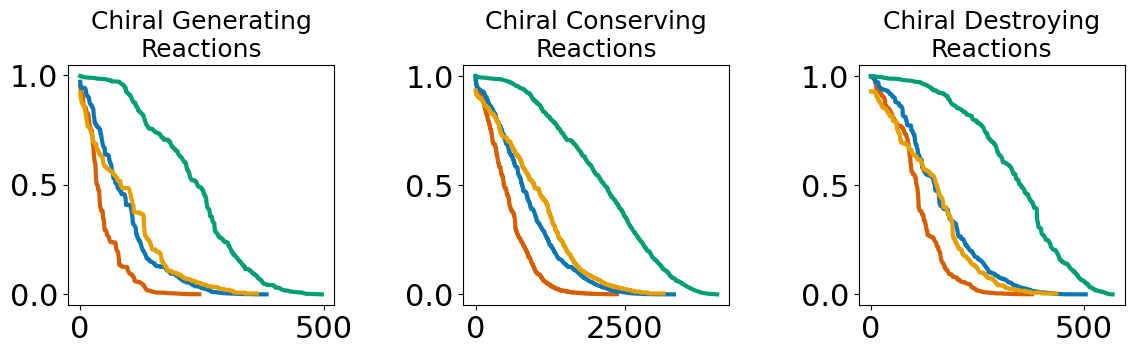

In [23]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(12,4))
gs = GridSpec(1,3)

ax_generate = fig.add_subplot(gs[0, 0])
ax_conserve = fig.add_subplot(gs[0,1])
ax_destroy = fig.add_subplot(gs[0, 2])

### Generation plot
a_generate = [u for r, u in a_rxn_universality.items() if r in chiral_generate_rxns]
b_generate = [u for r, u in b_rxn_universality.items() if r in chiral_generate_rxns]
e_generate = [u for r, u in e_rxn_universality.items() if r in chiral_generate_rxns]
m_generate = [u for r, u in m_rxn_universality.items() if r in chiral_generate_rxns]
ax_generate.plot(a_generate, linestyle="solid", linewidth=3, color=colors["archaea"], label="Archaea")
ax_generate.plot(b_generate, linestyle="solid", linewidth=3, color=colors["bacteria"], label="Bacteria")
ax_generate.plot(e_generate, linestyle="solid", linewidth=3, color=colors["eukarya"], label="Eukarya")
ax_generate.plot(m_generate, linestyle="solid", linewidth=3, color=colors["metagenome"], label="Metagenome")
ax_generate.set_title("Chiral Generating\nReactions", fontsize=18)

### Conserving plot
a_conserve = [u for r, u in a_rxn_universality.items() if r in chiral_conserve_rxns]
b_conserve = [u for r, u in b_rxn_universality.items() if r in chiral_conserve_rxns]
e_conserve = [u for r, u in e_rxn_universality.items() if r in chiral_conserve_rxns]
m_conserve = [u for r, u in m_rxn_universality.items() if r in chiral_conserve_rxns]
ax_conserve.plot(a_conserve, linestyle="solid", linewidth=3, color=colors["archaea"], label="Archaea")
ax_conserve.plot(b_conserve, linestyle="solid", linewidth=3, color=colors["bacteria"], label="Bacteria")
ax_conserve.plot(e_conserve, linestyle="solid", linewidth=3, color=colors["eukarya"], label="Eukarya")
ax_conserve.plot(m_conserve, linestyle="solid", linewidth=3, color=colors["metagenome"], label="Metagenome")
ax_conserve.set_title("Chiral Conserving\nReactions", fontsize=18)

### Destroying plot
a_destroy = [u for r, u in a_rxn_universality.items() if r in chiral_destroy_rxns]
b_destroy = [u for r, u in b_rxn_universality.items() if r in chiral_destroy_rxns]
e_destroy = [u for r, u in e_rxn_universality.items() if r in chiral_destroy_rxns]
m_destroy = [u for r, u in m_rxn_universality.items() if r in chiral_destroy_rxns]
ax_destroy.plot(a_destroy, linestyle="solid", linewidth=3, color=colors["archaea"], label="Archaea")
ax_destroy.plot(b_destroy, linestyle="solid", linewidth=3, color=colors["bacteria"], label="Bacteria")
ax_destroy.plot(e_destroy, linestyle="solid", linewidth=3, color=colors["eukarya"], label="Eukarya")
ax_destroy.plot(m_destroy, linestyle="solid", linewidth=3, color=colors["metagenome"], label="Metagenome")
ax_destroy.set_title("Chiral Destroying\nReactions", fontsize=18)

plt.tight_layout()

## Full Figure

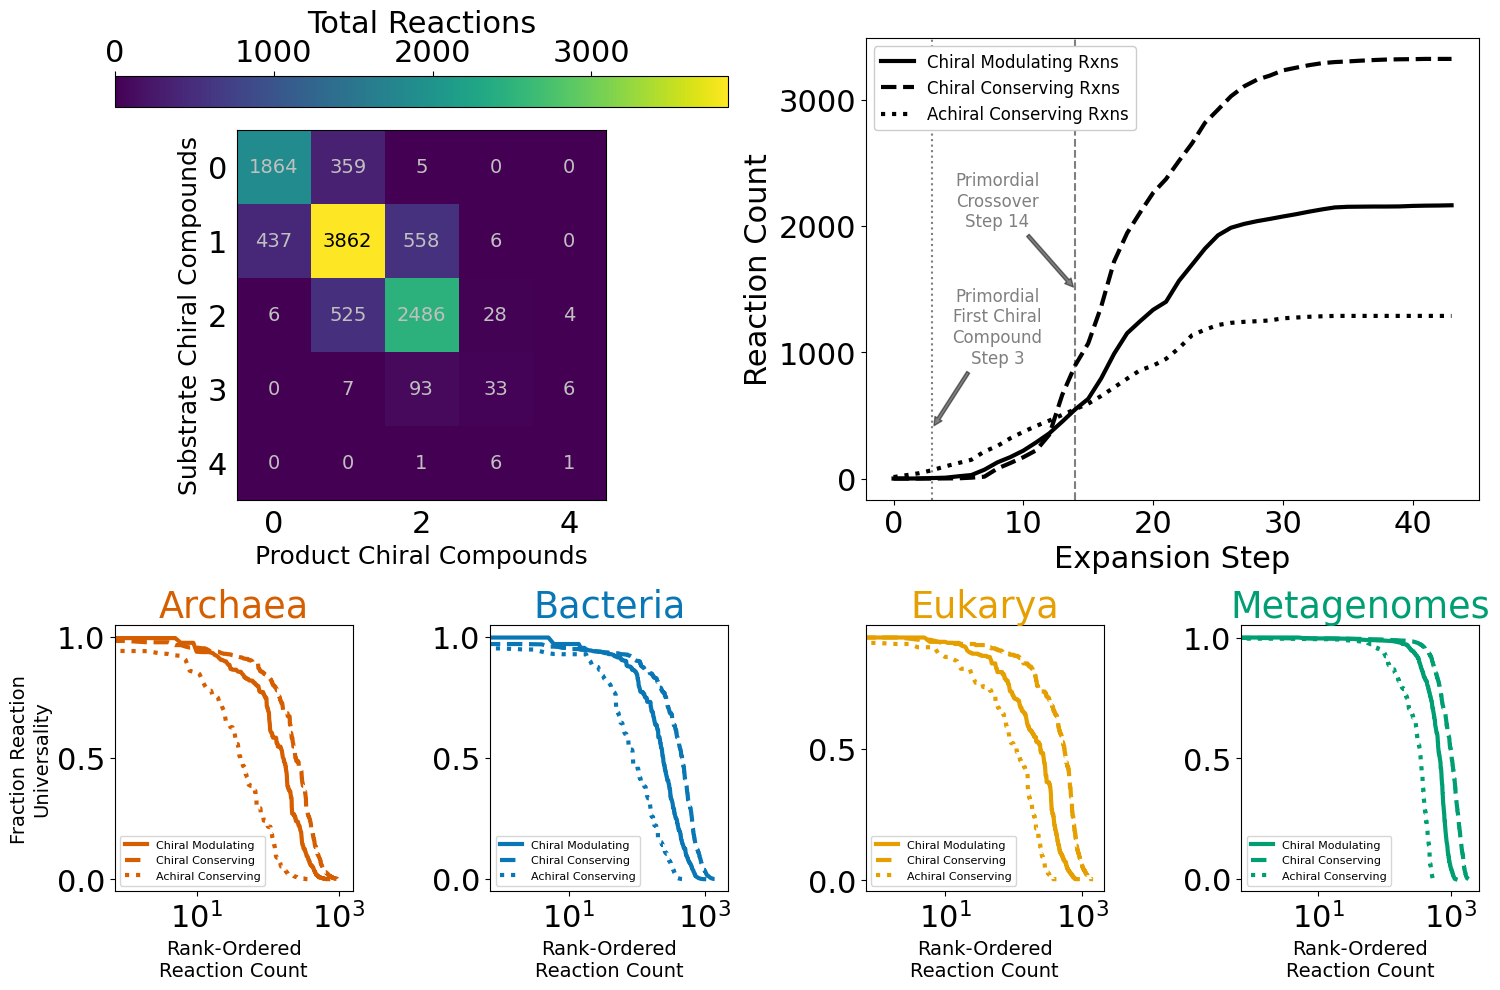

In [42]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(15,10))
gs = GridSpec(5,4)

ax1 = fig.add_subplot(gs[0:3, 0:2])
im = ax1.imshow(heatmap_array)

# ax1.set_yticklabels(["", 0, "", 1, "", 2])
# ax1.set_xticklabels(["", 0, 1, 2, "", ""])

ax1.tick_params(
    axis='both',          # changes apply to the x-axis
    which='both',      # both major and minor ticks are affected
    bottom=False,      # ticks along the bottom edge are off
    left=False)   

ax1.set_ylabel("Substrate Chiral Compounds", fontsize=18)
ax1.set_xlabel("Product Chiral Compounds", fontsize=18)

for i in range(5):
    for j in range(5):
        if i == 1 and j == 1:
            c = "k"
        else:
            c = "silver"
        text = ax1.text(j, i, heatmap_array[i][j],
                       ha = "center", va = "center", color = c, fontsize=14)

# # Add the color bar
cbar = ax1.figure.colorbar(im, ax = ax1, location="top")
cbar.ax.set_xlabel("Total Reactions")

ax2 = fig.add_subplot(gs[0:3, 2:])

ax2.plot(list(np.cumsum(np.array(modulating))), 
        linestyle="solid", linewidth=3, color='k', label="Chiral Modulating Rxns")
ax2.plot(list(np.cumsum(np.array(chiral_conserve))), 
        linestyle="dashed", linewidth=3, color='k', label="Chiral Conserving Rxns")
ax2.plot(list(np.cumsum(np.array(achiral_conserve))), linestyle="dotted", 
        linewidth=3, color='k', label="Achiral Conserving Rxns")

ax2.axvline(x=14, color="k", linestyle="--", alpha=0.5)
ax2.annotate("Primordial\nCrossover\nStep 14", xy=(14, 1500), xytext=(8,2200), color="k", alpha=0.5,
             arrowprops={"arrowstyle": "simple", "color": "k", "alpha": 0.5}, fontsize=12, ha='center', va='center', zorder=3)
ax2.axvline(x=3, color="k", linestyle=":", alpha=0.5)
ax2.annotate("Primordial\nFirst Chiral\nCompound\nStep 3", xy=(3, 400), xytext=(8,1200), color="k", alpha=0.5,
             arrowprops={"arrowstyle": "simple", "color": "k", "alpha": 0.5}, fontsize=12, ha='center', va='center', zorder=3)

ax2.legend(loc="upper left", facecolor="white", framealpha=1, prop={"size":12})
ax2.set_xlabel("Expansion Step")
ax2.set_ylabel("Reaction Count")


ax_archaea = fig.add_subplot(gs[3:, 0])
ax_bacteria = fig.add_subplot(gs[3:,1])
ax_eukarya= fig.add_subplot(gs[3:, 2])
ax_mg = fig.add_subplot(gs[3:, 3])

plot_classes(a_rxn_universality, ax_archaea, colors["archaea"], "Archaea")
plot_classes(b_rxn_universality, ax_bacteria, colors["bacteria"], "Bacteria")
plot_classes(e_rxn_universality, ax_eukarya, colors["eukarya"], "Eukarya")
plot_classes(m_rxn_universality, ax_mg, colors["metagenome"], "Metagenomes")

ax_archaea.set_xscale("log")
ax_bacteria.set_xscale("log")
ax_eukarya.set_xscale("log")
ax_mg.set_xscale("log")

ax_archaea.set_ylabel("Fraction Reaction\nUniversality", fontsize=14)
ax_archaea.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_bacteria.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_eukarya.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)
ax_mg.set_xlabel("Rank-Ordered\nReaction Count", fontsize=14)

plt.tight_layout(pad=0.5)

plt.savefig("fig5.svg", format="svg")